# Versión B — Redes Profundas: Pipeline Completo
## Evaluación, Optimización, Regularización e Interpretabilidad
### Ingeniería del Conocimiento (ISO56B) — Sesiones 05, 06 y 07
### UNCP — Facultad de Ingeniería de Sistemas
### Docente: Msc. Jaime Antonio Huaytalla Pariona | Semestre 2026-II

---

**Enfoque:** Redes Neuronales Convolucionales (CNNs) y arquitecturas profundas aplicadas a datos de imagen.

**Dataset:** Fashion-MNIST — clasificación de 10 categorías de prendas de vestir (28×28 px, escala de grises).

**Bloques temáticos:**
1. Datos y modelo base (CNN simple)
2. Evaluación — de lo simple a lo riguroso
3. Optimización y regularización (Data Augmentation, BN, Dropout, LR schedule, mini-ResNet)
4. Interpretabilidad y explicabilidad (filtros, feature maps, GradCAM, saliency maps)

> 🧠 Este notebook demuestra el flujo completo de un proyecto de visión por computadora con redes profundas, desde la exploración visual hasta la explicación de las decisiones del modelo mediante GradCAM.

In [1]:
# ============================================================
# CONFIGURACIÓN INICIAL
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# --- TensorFlow / Keras ---
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, regularizers

# --- Scikit-learn (métricas) ---
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, accuracy_score, f1_score
)
from sklearn.preprocessing import label_binarize

# --- Reproducibilidad ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- Estilo visual ---
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

# --- GPU ---
gpus = tf.config.list_physical_devices('GPU')
print(f"TensorFlow: {tf.__version__}")
if gpus:
    print(f"✅ GPU disponible: {gpus[0].name}")
else:
    print("⚠️ Sin GPU. En Colab: Runtime → Change runtime type → T4 GPU")

TensorFlow: 2.21.0
✅ GPU disponible: /physical_device:GPU:0


---
## BLOQUE 1 — Datos y Exploración Visual

**Fashion-MNIST** es un dataset de referencia en visión por computadora que reemplaza al clásico MNIST de dígitos. Contiene 70,000 imágenes en escala de grises (28×28 px) de 10 categorías de ropa y accesorios.

In [2]:
# ============================================================
# CARGA DEL DATASET
# ============================================================
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Nombres de las 10 clases (en español)
class_names = ['Camiseta', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo',
               'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Bota']

print("=" * 55)
print("INFORMACIÓN DEL DATASET — Fashion-MNIST")
print("=" * 55)
print(f"Entrenamiento: {x_train_full.shape} (uint8)")
print(f"Test:          {x_test.shape}")
print(f"Clases:        {len(class_names)}")
print(f"Píxeles:       [{x_train_full.min()}, {x_train_full.max()}]")
print(f"\nDistribución de clases (train):")
for i, name in enumerate(class_names):
    count = np.sum(y_train_full == i)
    print(f"  {i}: {name:12s} → {count:,} ({count/len(y_train_full)*100:.1f}%)")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
INFORMACIÓN DEL DATASET — Fashion-MNIST
Entrenamiento: (60000, 28, 28) (uint8)
Test:          (10000, 28, 28)
Clases:        10
Píxeles:       [0, 255]

Distribución de clases (train):
  0: Camiseta     → 6,000 (10.0%)
  1: Pantalón     → 6,000 (10.0%)
  2: Suéter       → 6,000 (10.0%)
  3: Vestido      → 6,000 (10.0%)
  4: Abrigo       → 6,000 (10.0%)
  5: Sandalia     → 6,000 (10.0%)
  6: Camisa       → 6,000 (10.0%)
  7: Zapatilla    → 6,000 (10.0%)
  8: Bolso        → 6,000 (10.0%)
  9: Bota         → 6,000 (10.0%)


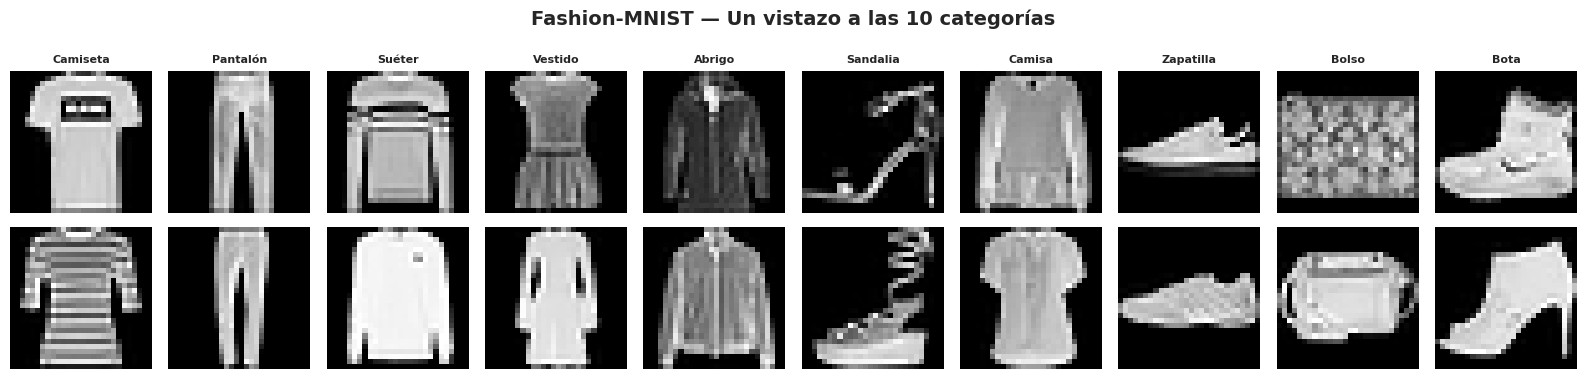

In [3]:
# ============================================================
# VISUALIZACIÓN DE EJEMPLOS
# ============================================================
fig, axes = plt.subplots(2, 10, figsize=(16, 4))

# Fila 1: un ejemplo de cada clase
for i in range(10):
    idx = np.where(y_train_full == i)[0][0]
    axes[0, i].imshow(x_train_full[idx], cmap='gray')
    axes[0, i].set_title(class_names[i], fontsize=8, fontweight='bold')
    axes[0, i].axis('off')

# Fila 2: otro ejemplo aleatorio de cada clase
for i in range(10):
    idx = np.where(y_train_full == i)[0][5]
    axes[1, i].imshow(x_train_full[idx], cmap='gray')
    axes[1, i].axis('off')

plt.suptitle('Fashion-MNIST — Un vistazo a las 10 categorías', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:
# ============================================================
# PREPROCESAMIENTO
# ============================================================
# 1. Normalizar píxeles a [0, 1]
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# 2. Añadir dimensión de canal: (28, 28) → (28, 28, 1)
#    Las CNNs de Keras esperan tensores de 4 dimensiones: (batch, alto, ancho, canales)
x_train_full = x_train_full[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# 3. Separar validación (10% del training)
from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.10,
    random_state=SEED, stratify=y_train_full
)

print(f"Train: {x_train.shape[0]:,} | Val: {x_val.shape[0]:,} | Test: {x_test.shape[0]:,}")
print(f"Shape de una imagen: {x_train[0].shape}")
print(f"Rango de píxeles: [{x_train.min():.1f}, {x_train.max():.1f}]")

Train: 54,000 | Val: 6,000 | Test: 10,000
Shape de una imagen: (28, 28, 1)
Rango de píxeles: [0.0, 1.0]


---
## BLOQUE 2 — Evaluación: De lo Simple a lo Riguroso

Construimos una CNN base y la evaluamos progresivamente:
- **Simple:** accuracy global y curvas de aprendizaje
- **Rigurosa:** matriz de confusión, reporte por clase, curvas ROC multiclase, análisis de errores

In [5]:
# ============================================================
# FUNCIÓN UTILITARIA — Curvas de entrenamiento
# ============================================================
def graficar_historia(history, titulo=''):
    """Grafica accuracy y loss con diagnóstico de overfitting."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(history.history['accuracy'], label='Train', linewidth=2)
    ax1.plot(history.history['val_accuracy'], label='Val', linewidth=2)
    ax1.set_title(f'Accuracy — {titulo}', fontweight='bold')
    ax1.set_xlabel('Época'); ax1.set_ylabel('Accuracy')
    ax1.legend(); ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'], label='Train', linewidth=2)
    ax2.plot(history.history['val_loss'], label='Val', linewidth=2)
    ax2.set_title(f'Loss — {titulo}', fontweight='bold')
    ax2.set_xlabel('Época'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    final_train = history.history['accuracy'][-1]
    final_val = history.history['val_accuracy'][-1]
    brecha = final_train - final_val
    print(f"  Train: {final_train:.4f} | Val: {final_val:.4f} | Brecha: {brecha:.4f}")
    if brecha > 0.05:
        print(f"  ⚠️  Posible OVERFITTING")
    else:
        print(f"  ✅ Buen ajuste")

print("✅ Funciones utilitarias definidas.")

✅ Funciones utilitarias definidas.


In [6]:
# ============================================================
# CNN BASE — Arquitectura simple sin regularización
# ============================================================
# Arquitectura:
#   Conv(32) → Conv(32) → MaxPool → Conv(64) → Conv(64) → MaxPool
#   → Flatten → Dense(128) → Dense(10, softmax)
#
# SIN Dropout, SIN BatchNorm, SIN Data Augmentation
# Esto nos permite ver el overfitting "puro"

model_base = models.Sequential([
    # Bloque conv 1: detectar bordes y texturas simples
    layers.Conv2D(32, (3, 3), activation='relu', padding='same',
                  input_shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),  # 28×28 → 14×14

    # Bloque conv 2: detectar patrones más complejos
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),  # 14×14 → 7×7

    # Clasificador
    layers.Flatten(),          # 7×7×64 = 3,136 valores
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 clases → softmax
], name='CNN_Base')

model_base.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # Para etiquetas enteras
    metrics=['accuracy']
)

model_base.summary()
print(f"\nParámetros totales: {model_base.count_params():,}")

Model: "CNN_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 467,818 (1.78 MB)

 Trainable params: 467,818 (1.78 MB)

 Non-trainable params: 0 (0.00 B)


Parámetros totales: 467,818


In [7]:
# ============================================================
# ENTRENAMIENTO CNN BASE
# ============================================================
history_base = model_base.fit(
    x_train, y_train,
    batch_size=128,
    epochs=25,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.8270 - loss: 0.4759 - val_accuracy: 0.8875 - val_loss: 0.3128
Epoch 2/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8972 - loss: 0.2836 - val_accuracy: 0.9075 - val_loss: 0.2606
Epoch 3/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9157 - loss: 0.2291 - val_accuracy: 0.9182 - val_loss: 0.2258
Epoch 4/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9295 - loss: 0.1927 - val_accuracy: 0.9235 - val_loss: 0.2222
Epoch 5/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9394 - loss: 0.1648 - val_accuracy: 0.9222 - val_loss: 0.2270
Epoch 6/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9485 - loss: 0.1412 - val_accuracy: 0.9222 - val_loss: 0.2446
Epoch 7/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9560 - loss: 0.1193 - val_accuracy: 0.9173 - val_loss: 0.2881
Epoch 8/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9647 - loss: 0.0971 - val_accuracy:

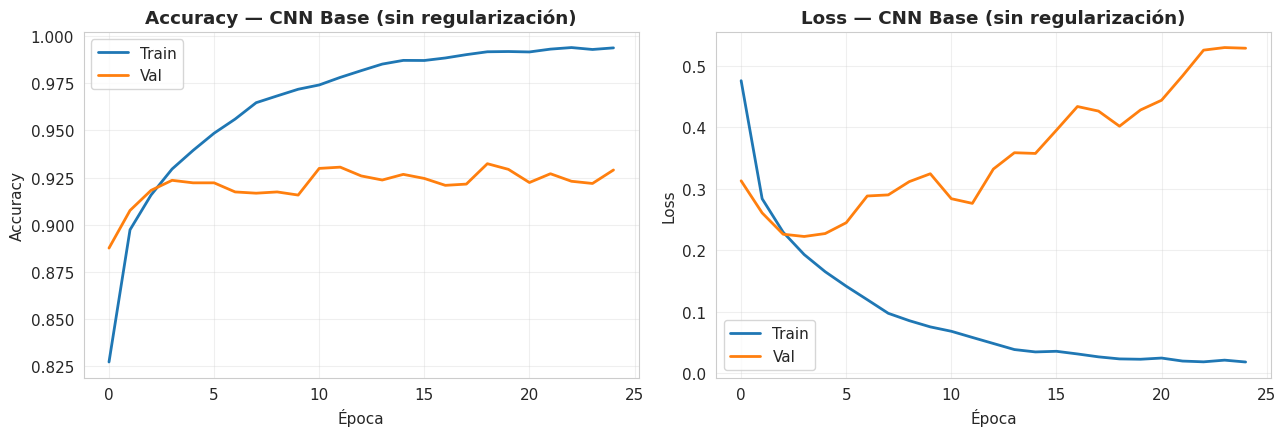

  Train: 0.9939 | Val: 0.9290 | Brecha: 0.0649
  ⚠️  Posible OVERFITTING


In [8]:
# ============================================================
# 2.1 EVALUACIÓN SIMPLE — Curvas de aprendizaje
# ============================================================
graficar_historia(history_base, 'CNN Base (sin regularización)')

REPORTE DE CLASIFICACIÓN — CNN Base (Test acc: 0.9206)
              precision    recall  f1-score   support

    Camiseta     0.8321    0.9020    0.8656      1000
    Pantalón     0.9890    0.9890    0.9890      1000
      Suéter     0.9035    0.8710    0.8870      1000
     Vestido     0.9152    0.9280    0.9215      1000
      Abrigo     0.8794    0.8820    0.8807      1000
    Sandalia     0.9821    0.9860    0.9840      1000
      Camisa     0.7863    0.7320    0.7582      1000
   Zapatilla     0.9622    0.9680    0.9651      1000
       Bolso     0.9830    0.9810    0.9820      1000
        Bota     0.9709    0.9670    0.9689      1000

    accuracy                         0.9206     10000
   macro avg     0.9204    0.9206    0.9202     10000
weighted avg     0.9204    0.9206    0.9202     10000



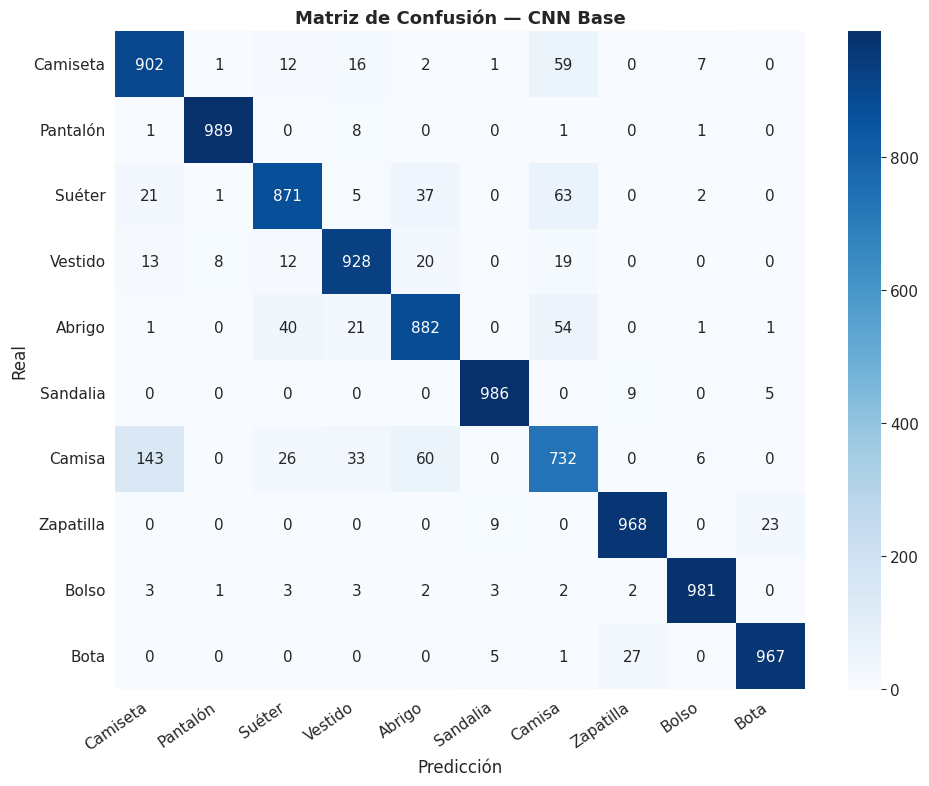


Top 3 confusiones más frecuentes:
  Camisa → confundido como Camiseta (143 veces)
  Suéter → confundido como Camisa (63 veces)
  Camisa → confundido como Abrigo (60 veces)


In [9]:
# ============================================================
# 2.2 EVALUACIÓN RIGUROSA — Métricas por clase
# ============================================================
loss_base, acc_base = model_base.evaluate(x_test, y_test, verbose=0)
y_pred_base = np.argmax(model_base.predict(x_test, verbose=0), axis=1)

print("=" * 60)
print(f"REPORTE DE CLASIFICACIÓN — CNN Base (Test acc: {acc_base:.4f})")
print("=" * 60)
print(classification_report(y_test, y_pred_base,
      target_names=class_names, digits=4))

# --- Matriz de confusión ---
cm = confusion_matrix(y_test, y_pred_base)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel('Predicción', fontsize=12)
ax.set_ylabel('Real', fontsize=12)
ax.set_title('Matriz de Confusión — CNN Base', fontweight='bold', fontsize=13)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# Identificar los pares más confundidos
np.fill_diagonal(cm, 0)  # Ignorar diagonales
top_confusions = []
for _ in range(3):
    i, j = np.unravel_index(cm.argmax(), cm.shape)
    top_confusions.append((class_names[i], class_names[j], cm[i, j]))
    cm[i, j] = 0

print("\nTop 3 confusiones más frecuentes:")
for real, pred, count in top_confusions:
    print(f"  {real} → confundido como {pred} ({count} veces)")

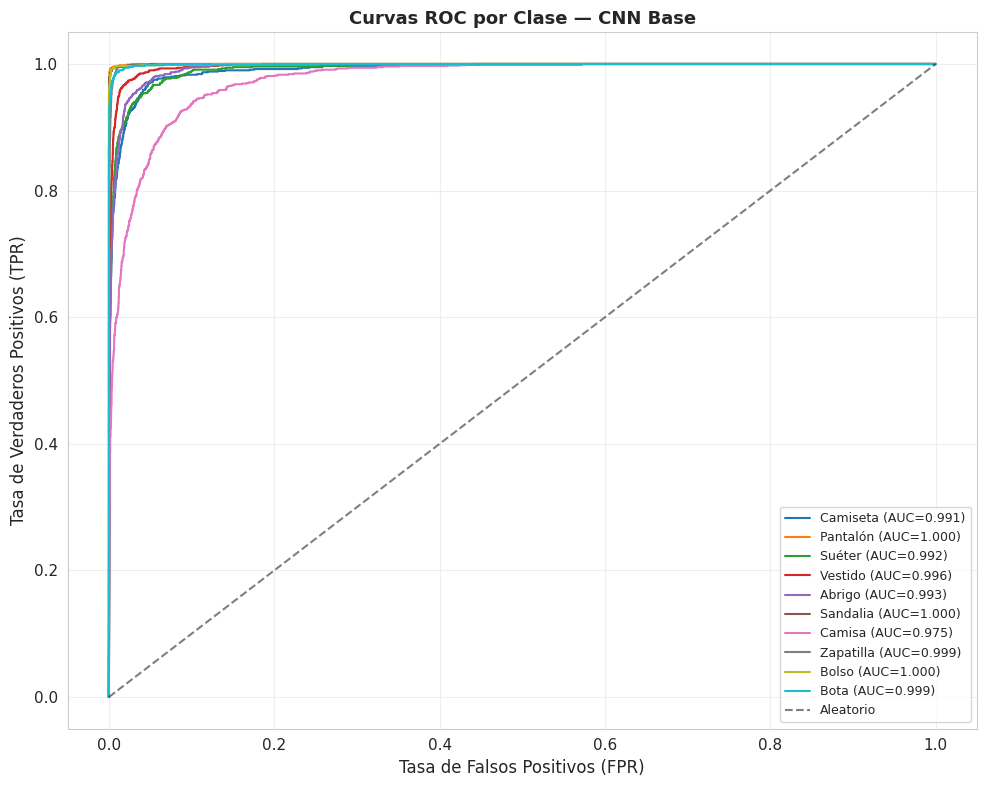

AUC promedio (macro): 0.9946
Clase con peor AUC: Camisa (0.9753)
Clase con mejor AUC: Pantalón (0.9998)


In [10]:
# ============================================================
# 2.3 CURVAS ROC MULTICLASE (One-vs-Rest)
# ============================================================
# Para clasificación multiclase, calculamos ROC para cada clase
# usando el esquema One-vs-Rest (OvR)

# Obtener probabilidades por clase
y_pred_proba = model_base.predict(x_test, verbose=0)  # shape: (10000, 10)
y_test_bin = label_binarize(y_test, classes=range(10))  # One-hot: (10000, 10)

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, 10))

auc_scores = []
for i in range(10):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_auc = auc(fpr, tpr)
    auc_scores.append(roc_auc)
    ax.plot(fpr, tpr, color=colors[i], linewidth=1.5,
            label=f'{class_names[i]} (AUC={roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
ax.set_title('Curvas ROC por Clase — CNN Base', fontweight='bold', fontsize=13)
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"AUC promedio (macro): {np.mean(auc_scores):.4f}")
print(f"Clase con peor AUC: {class_names[np.argmin(auc_scores)]} ({min(auc_scores):.4f})")
print(f"Clase con mejor AUC: {class_names[np.argmax(auc_scores)]} ({max(auc_scores):.4f})")

Total de errores: 794 de 10000 (7.9%)


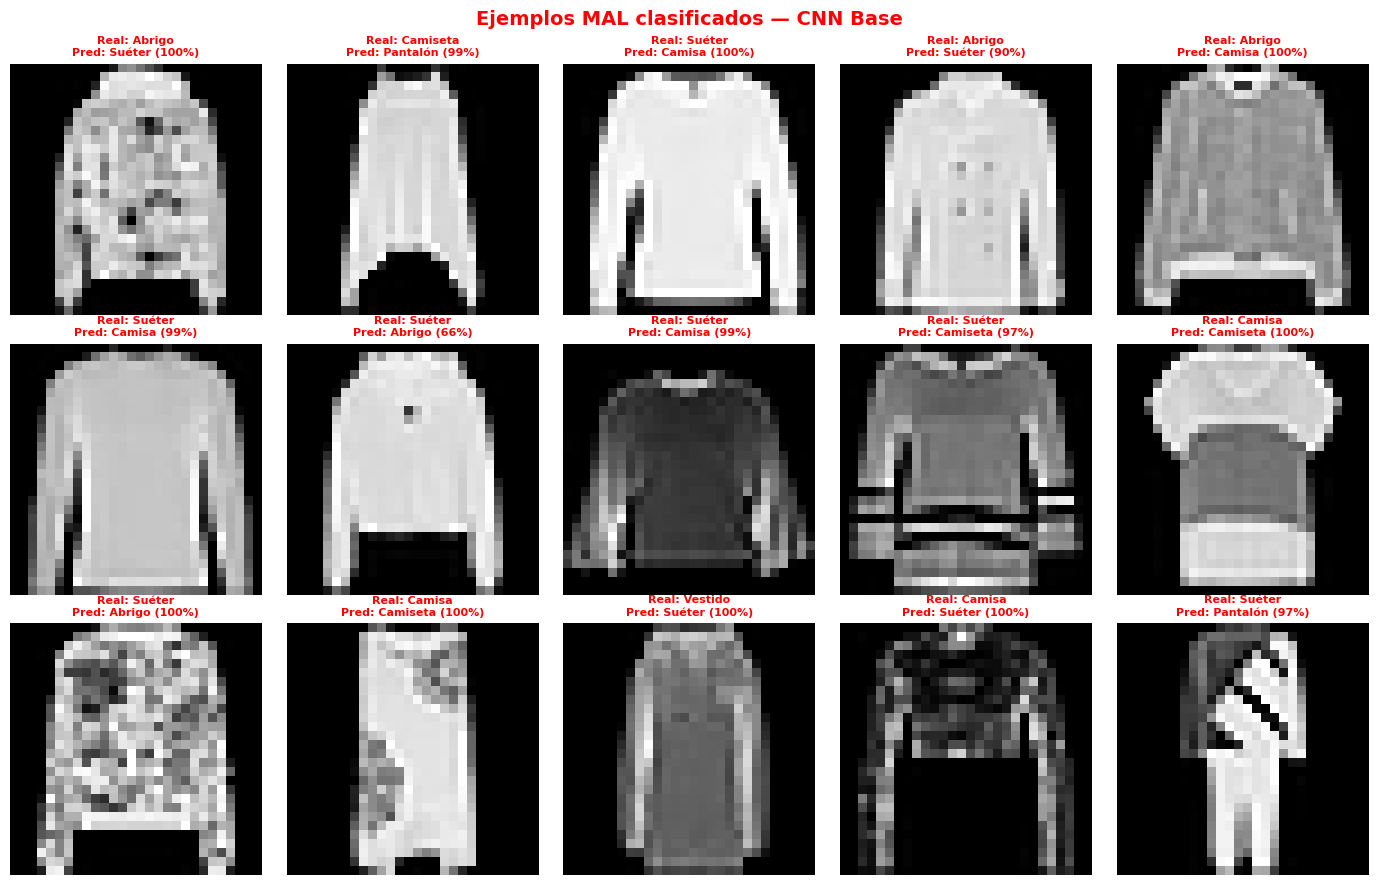


Errores por clase:
  Camiseta    :  98/1000 errores (  9.8%)
  Pantalón    :  11/1000 errores (  1.1%)
  Suéter      : 129/1000 errores ( 12.9%)
  Vestido     :  72/1000 errores (  7.2%)
  Abrigo      : 118/1000 errores ( 11.8%)
  Sandalia    :  14/1000 errores (  1.4%)
  Camisa      : 268/1000 errores ( 26.8%)
  Zapatilla   :  32/1000 errores (  3.2%)
  Bolso       :  19/1000 errores (  1.9%)
  Bota        :  33/1000 errores (  3.3%)


In [11]:
# ============================================================
# 2.4 ANÁLISIS DE ERRORES — ¿Qué falla?
# ============================================================
# Visualizamos ejemplos mal clasificados para entender los errores

errores = np.where(y_pred_base != y_test)[0]
print(f"Total de errores: {len(errores)} de {len(y_test)} ({len(errores)/len(y_test)*100:.1f}%)")

# Mostrar 15 ejemplos mal clasificados
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
np.random.seed(SEED)
sample_errors = np.random.choice(errores, min(15, len(errores)), replace=False)

for ax, idx in zip(axes.flat, sample_errors):
    ax.imshow(x_test[idx].squeeze(), cmap='gray')
    real = class_names[y_test[idx]]
    pred = class_names[y_pred_base[idx]]
    conf = y_pred_proba[idx][y_pred_base[idx]] * 100
    ax.set_title(f'Real: {real}\nPred: {pred} ({conf:.0f}%)',
                 fontsize=8, color='red', fontweight='bold')
    ax.axis('off')

plt.suptitle('Ejemplos MAL clasificados — CNN Base',
             fontsize=14, fontweight='bold', color='red')
plt.tight_layout()
plt.show()

# Errores por clase
print("\nErrores por clase:")
for i, name in enumerate(class_names):
    mask = y_test == i
    err = np.sum(y_pred_base[mask] != i)
    total = np.sum(mask)
    print(f"  {name:12s}: {err:3d}/{total} errores ({err/total*100:5.1f}%)")

---
## BLOQUE 3 — Optimización y Regularización

Aplicamos técnicas progresivas para mejorar la CNN base:
1. **Data Augmentation** — expandir el dataset con transformaciones
2. **BatchNorm + Dropout** — estabilizar y regularizar
3. **Comparación de optimizadores** — SGD vs Adam
4. **Mini-ResNet** — conexiones residuales (skip connections)
5. **Callbacks** — EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

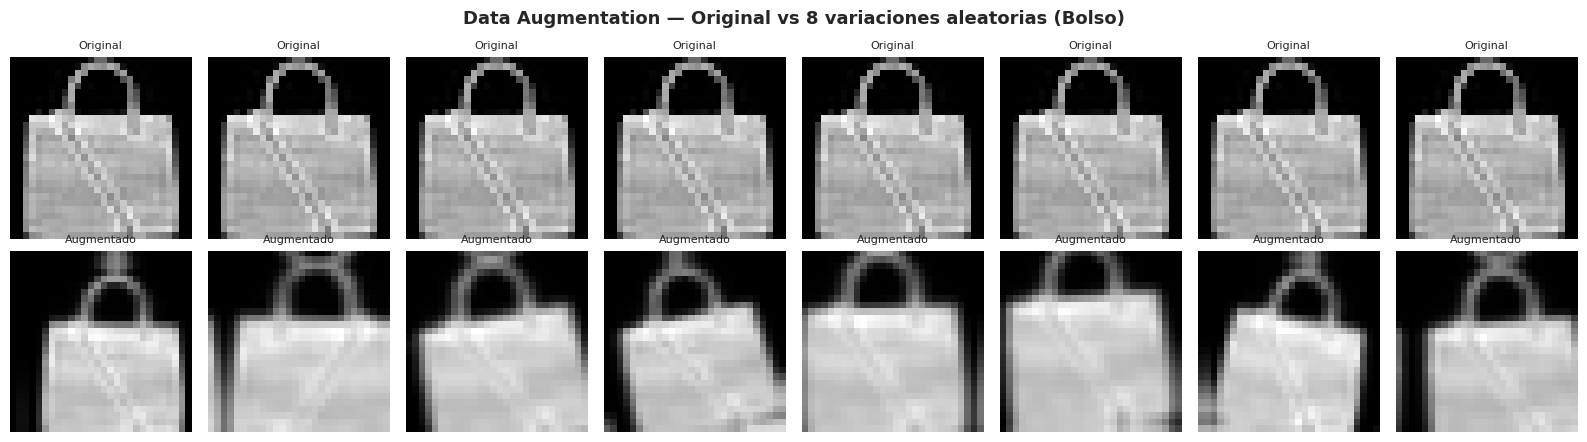

In [12]:
# ============================================================
# 3.1 DATA AUGMENTATION
# ============================================================
# Genera variaciones de las imágenes para aumentar la diversidad
# del entrenamiento SIN más datos reales.
# Se aplica SOLO durante entrenamiento (training=True).

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),         # Espejo horizontal
    layers.RandomRotation(0.05),              # Rotación ±18°
    layers.RandomZoom((-0.1, 0.1)),           # Zoom ±10%
    layers.RandomTranslation(0.1, 0.1),       # Desplazamiento ±10%
], name='DataAugmentation')

# Visualizar el efecto
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
img_orig = x_train[0:1]  # Una imagen original

# Primera fila: imagen original repetida
for ax in axes[0]:
    ax.imshow(img_orig[0].squeeze(), cmap='gray')
    ax.set_title('Original', fontsize=8)
    ax.axis('off')

# Segunda fila: augmentaciones aleatorias
for ax in axes[1]:
    augmented = data_augmentation(img_orig, training=True)
    ax.imshow(augmented[0].numpy().squeeze(), cmap='gray')
    ax.set_title('Augmentado', fontsize=8)
    ax.axis('off')

plt.suptitle(f'Data Augmentation — Original vs 8 variaciones aleatorias ({class_names[y_train[0]]})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Entrenando con SGD (lr=0.01)... val_acc = 0.8747
Entrenando con SGD + Momentum... val_acc = 0.9142
Entrenando con Adam (lr=0.001)... val_acc = 0.9277


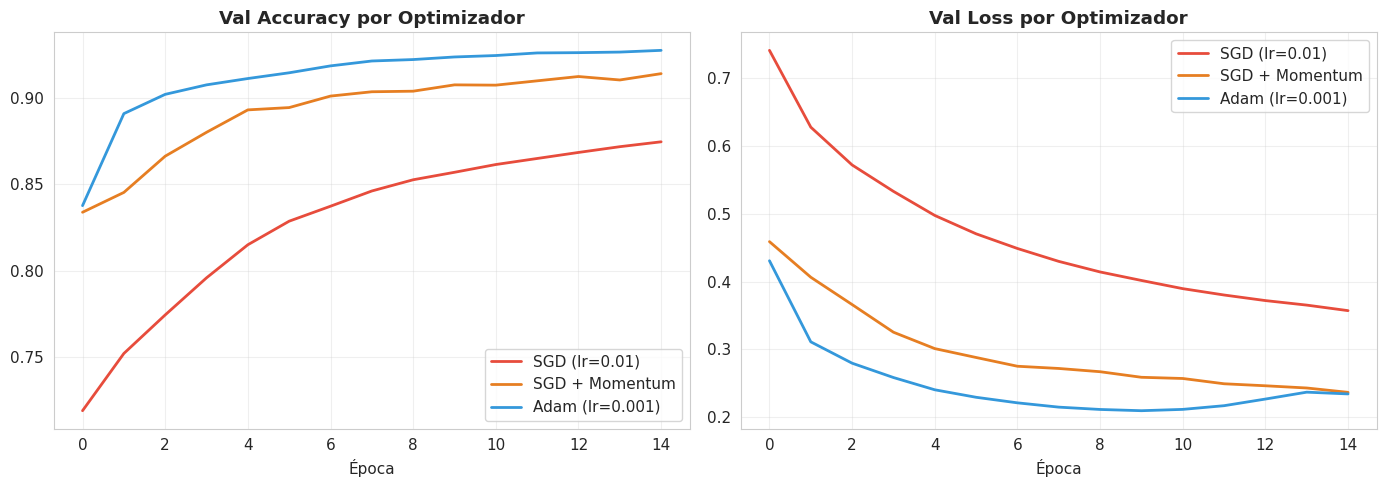

In [13]:
# ============================================================
# 3.2 COMPARACIÓN DE OPTIMIZADORES
# ============================================================
def crear_cnn_simple():
    """Fábrica de CNNs idénticas para comparación justa."""
    return models.Sequential([
        layers.Conv2D(32, 3, activation='relu', padding='same', input_shape=(28, 28, 1)),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

optimizers = {
    'SGD (lr=0.01)': tf.keras.optimizers.SGD(learning_rate=0.01),
    'SGD + Momentum': tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'Adam (lr=0.001)': tf.keras.optimizers.Adam(learning_rate=0.001),
}

historias_opt = {}
for name, opt in optimizers.items():
    print(f"Entrenando con {name}...", end=' ')
    m = crear_cnn_simple()
    m.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(x_train, y_train, batch_size=128, epochs=15,
              validation_data=(x_val, y_val), verbose=0)
    historias_opt[name] = h
    print(f"val_acc = {h.history['val_accuracy'][-1]:.4f}")

# Visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors_opt = ['#e74c3c', '#e67e22', '#3498db']
for (name, h), c in zip(historias_opt.items(), colors_opt):
    ax1.plot(h.history['val_accuracy'], label=name, linewidth=2, color=c)
    ax2.plot(h.history['val_loss'], label=name, linewidth=2, color=c)

ax1.set_title('Val Accuracy por Optimizador', fontweight='bold')
ax1.set_xlabel('Época'); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.set_title('Val Loss por Optimizador', fontweight='bold')
ax2.set_xlabel('Época'); ax2.legend(); ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# 3.3 CNN MEJORADA — BN + Dropout + Augmentation + GAP
# ============================================================
# Patrón moderno: Conv → BN → ReLU (con use_bias=False)
# Global Average Pooling reemplaza Flatten+Dense (menos parámetros)

def crear_cnn_mejorada(input_shape=(28, 28, 1), num_classes=10):
    inputs = layers.Input(shape=input_shape)
    x = data_augmentation(inputs)  # Solo se aplica en training

    # Bloque 1: 32 filtros
    x = layers.Conv2D(32, 3, padding='same', use_bias=False,
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(32, 3, padding='same', use_bias=False,
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)  # 28→14
    x = layers.Dropout(0.25)(x)

    # Bloque 2: 64 filtros
    x = layers.Conv2D(64, 3, padding='same', use_bias=False,
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(64, 3, padding='same', use_bias=False,
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)  # 14→7
    x = layers.Dropout(0.25)(x)

    # Bloque 3: 128 filtros
    x = layers.Conv2D(128, 3, padding='same', use_bias=False,
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Clasificador con Global Average Pooling
    x = layers.GlobalAveragePooling2D()(x)  # 7×7×128 → 128
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs, name='CNN_Mejorada')

model_mejorada = crear_cnn_mejorada()
model_mejorada.summary()
print(f"\nParámetros: {model_mejorada.count_params():,} (vs {model_base.count_params():,} del base)")

Model: "CNN_Mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DataAugmentation (Sequential)   │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 141,098 (551.16 KB)

 Trainable params: 140,458 (548.66 KB)

 Non-trainable params: 640 (2.50 KB)


Parámetros: 141,098 (vs 467,818 del base)


In [15]:
# ============================================================
# ENTRENAR CNN MEJORADA CON CALLBACKS
# ============================================================
model_mejorada.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_mejorada = [
    callbacks.EarlyStopping(monitor='val_loss', patience=10,
                           restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                               patience=4, min_lr=1e-6, verbose=1),
]

history_mejorada = model_mejorada.fit(
    x_train, y_train,
    batch_size=128,
    epochs=60,
    validation_data=(x_val, y_val),
    callbacks=callbacks_mejorada,
    verbose=1
)

Epoch 1/60
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - accuracy: 0.6824 - loss: 0.8792 - val_accuracy: 0.7740 - val_loss: 0.6283 - learning_rate: 0.0010
Epoch 2/60
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.7803 - loss: 0.5991 - val_accuracy: 0.8202 - val_loss: 0.5056 - learning_rate: 0.0010
Epoch 3/60
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8039 - loss: 0.5339 - val_accuracy: 0.8293 - val_loss: 0.4765 - learning_rate: 0.0010
Epoch 4/60
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8187 - loss: 0.4945 - val_accuracy: 0.8410 - val_loss: 0.4498 - learning_rate: 0.0010
Epoch 5/60
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8288 - loss: 0.4693 - val_accuracy: 0.8442 - val_loss: 0.4245 - learning_rate: 0.0010
Epoch 6/60
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8349 - loss: 0.4481 - val_accuracy: 0.8692 - val_loss: 0.3615 - learning_rate: 0.0010
Epoch 7/60
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8412 - loss: 0

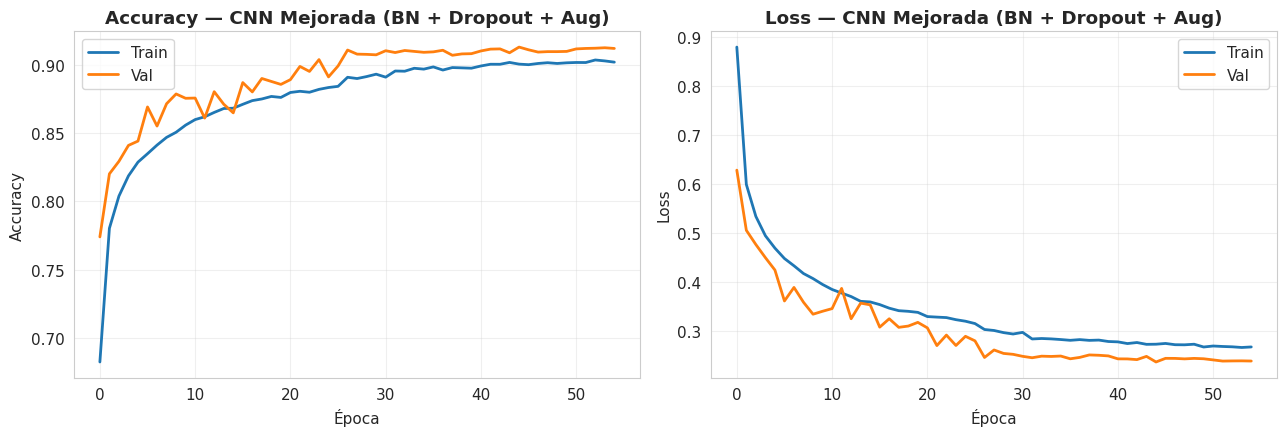

  Train: 0.9020 | Val: 0.9120 | Brecha: -0.0100
  ✅ Buen ajuste

CNN Base     → Test accuracy: 0.9206
CNN Mejorada → Test accuracy: 0.9001
Mejora: +-2.05 puntos porcentuales


In [16]:
# Curvas y evaluación de la CNN mejorada
graficar_historia(history_mejorada, 'CNN Mejorada (BN + Dropout + Aug)')

loss_mej, acc_mej = model_mejorada.evaluate(x_test, y_test, verbose=0)
print(f"\nCNN Base     → Test accuracy: {acc_base:.4f}")
print(f"CNN Mejorada → Test accuracy: {acc_mej:.4f}")
print(f"Mejora: +{(acc_mej - acc_base)*100:.2f} puntos porcentuales")

In [17]:
# ============================================================
# 3.4 MINI-RESNET — Conexiones residuales (skip connections)
# ============================================================
# La idea central de ResNet: en vez de aprender F(x), aprendemos F(x) + x
# Esto permite entrenar redes más profundas sin degradación de gradientes

def bloque_residual(x, filtros, stride=1):
    """Bloque residual básico: 2 convoluciones + skip connection.

    Si stride > 1 o los filtros cambian, el shortcut usa Conv2D 1×1
    para ajustar las dimensiones antes de la suma.
    """
    shortcut = x

    # Rama principal: Conv → BN → ReLU → Conv → BN
    out = layers.Conv2D(filtros, 3, strides=stride, padding='same',
                        use_bias=False, kernel_initializer='he_normal')(x)
    out = layers.BatchNormalization()(out)
    out = layers.ReLU()(out)

    out = layers.Conv2D(filtros, 3, strides=1, padding='same',
                        use_bias=False, kernel_initializer='he_normal')(out)
    out = layers.BatchNormalization()(out)

    # Proyección del shortcut si las dimensiones no coinciden
    if stride != 1 or x.shape[-1] != filtros:
        shortcut = layers.Conv2D(filtros, 1, strides=stride,
                                 use_bias=False,
                                 kernel_initializer='he_normal')(x)
        shortcut = layers.BatchNormalization()(shortcut)

    # Suma residual: F(x) + x
    out = layers.Add()([out, shortcut])
    out = layers.ReLU()(out)  # ReLU después de la suma
    return out


def crear_mini_resnet(input_shape=(28, 28, 1), num_classes=10):
    """Mini-ResNet adaptada a Fashion-MNIST (28×28).
    Estructura: Conv inicial → 3 grupos residuales → GAP → Dense.
    """
    inputs = layers.Input(shape=input_shape)
    x = data_augmentation(inputs)

    # Convolución inicial: no cambia dimensión espacial
    x = layers.Conv2D(32, 3, padding='same', use_bias=False,
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Grupo 1: 32 filtros, 28×28 → se mantiene
    x = bloque_residual(x, 32, stride=1)
    x = bloque_residual(x, 32, stride=1)

    # Grupo 2: 64 filtros, 28→14 (stride=2 en el primer bloque)
    x = bloque_residual(x, 64, stride=2)
    x = bloque_residual(x, 64, stride=1)

    # Grupo 3: 128 filtros, 14→7
    x = bloque_residual(x, 128, stride=2)
    x = bloque_residual(x, 128, stride=1)

    # Clasificador
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax',
                          kernel_initializer='he_normal')(x)

    return models.Model(inputs, outputs, name='Mini_ResNet')

model_resnet = crear_mini_resnet()
model_resnet.summary()
print(f"\nParámetros Mini-ResNet: {model_resnet.count_params():,}")

Model: "Mini_ResNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DataAugmentation    │ (None, 28, 28, 1) │          0 │ input_layer_6[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 28, 28,    │        288 │ DataAugmentation… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_15[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 28, 28,    │      9,216 │ re_lu_5[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_16[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_6 (ReLU)      │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 28, 28,    │      9,216 │ re_lu_6[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_17[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ re_lu_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_7 (ReLU)      │ (None, 28, 28,    │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 28, 28,    │      9,216 │ re_lu_7[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_8 (ReLU)      │ (None, 28, 28,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 28, 28,    │      9,216 │ re_lu_8[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        128 │ conv2d_19[0][0] 

 Total params: 698,282 (2.66 MB)

 Trainable params: 696,042 (2.66 MB)

 Non-trainable params: 2,240 (8.75 KB)


Parámetros Mini-ResNet: 698,282


In [18]:
# ============================================================
# ENTRENAR MINI-RESNET
# ============================================================
# Usamos SGD + Momentum con LR schedule (como en el paper original)
def lr_schedule(epoch, lr):
    if epoch in [40, 60]:
        return lr * 0.1
    return lr

model_resnet.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.05, momentum=0.9,
                                      weight_decay=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_resnet = [
    callbacks.LearningRateScheduler(lr_schedule, verbose=1),
    callbacks.ModelCheckpoint('mini_resnet_mejor.keras',
                             monitor='val_accuracy',
                             save_best_only=True, verbose=1),
]

history_resnet = model_resnet.fit(
    x_train, y_train,
    batch_size=128,
    epochs=80,
    validation_data=(x_val, y_val),
    callbacks=callbacks_resnet,
    verbose=1
)


Epoch 1: LearningRateScheduler setting learning rate to 0.05000000074505806.
Epoch 1/80
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.6317 - loss: 0.9988
Epoch 1: val_accuracy improved from None to 0.64933, saving model to mini_resnet_mejor.keras

Epoch 1: finished saving model to mini_resnet_mejor.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 56ms/step - accuracy: 0.7288 - loss: 0.7266 - val_accuracy: 0.6493 - val_loss: 0.9921 - learning_rate: 0.0500

Epoch 2: LearningRateScheduler setting learning rate to 0.05000000074505806.
Epoch 2/80
421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.8101 - loss: 0.5191
Epoch 2: val_accuracy improved from 0.64933 to 0.78917, saving model to mini_resnet_mejor.keras

Epoch 2: finished saving model to mini_resnet_mejor.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 55ms/step - accuracy: 0.8213 - loss: 0.4858 - val_accuracy: 0.7892 - val_loss: 0.6165 - learning_rate: 0.0500

Epoch 3: LearningRateScheduler setting learning rate to 0.05000000074505806.

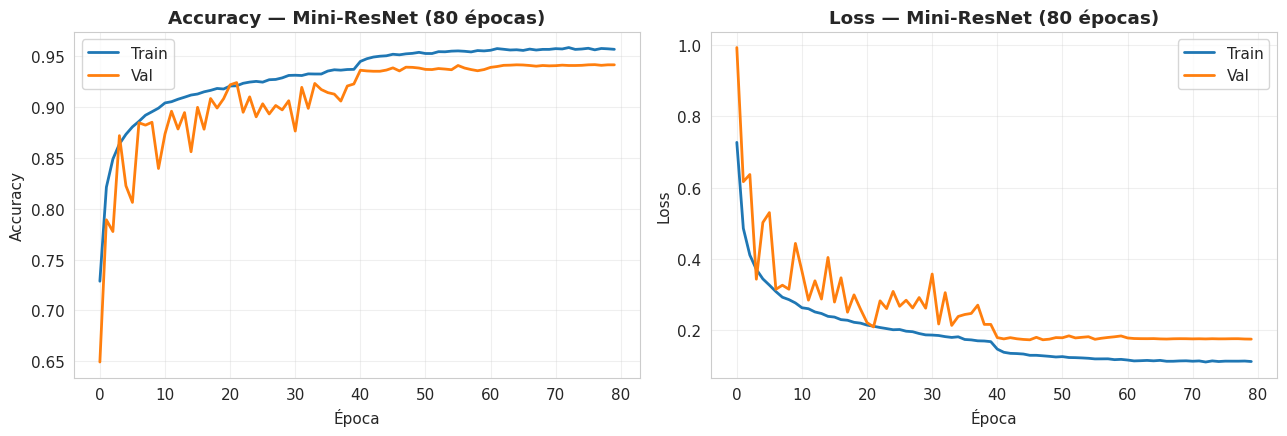

  Train: 0.9569 | Val: 0.9417 | Brecha: 0.0152
  ✅ Buen ajuste

COMPARACIÓN DE MODELOS
Modelo                        Params   Test Acc  Test Loss
------------------------------------------------------------
CNN Base                     467,818     0.9206     0.5923
CNN Mejorada                 141,098     0.9001     0.2746
Mini-ResNet                  698,282     0.9308     0.2063


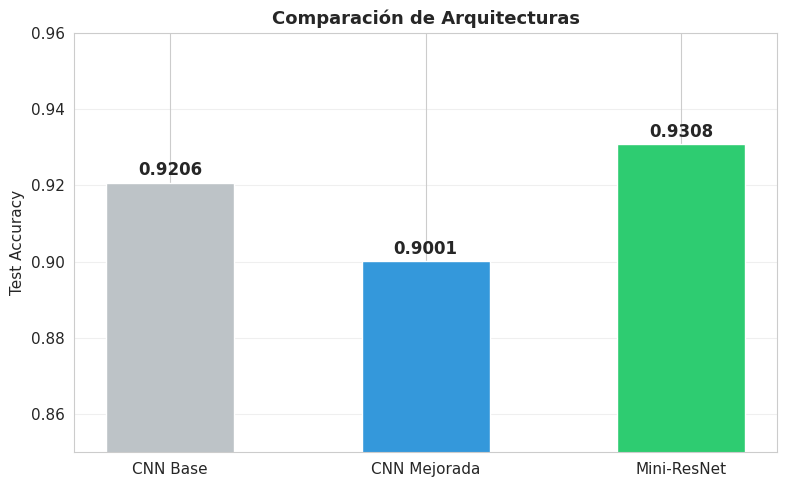

In [19]:
# ============================================================
# COMPARACIÓN DE LOS TRES MODELOS
# ============================================================
graficar_historia(history_resnet, 'Mini-ResNet (80 épocas)')

loss_res, acc_res = model_resnet.evaluate(x_test, y_test, verbose=0)

print("\n" + "=" * 60)
print("COMPARACIÓN DE MODELOS")
print("=" * 60)
print(f"{'Modelo':<25} {'Params':>10} {'Test Acc':>10} {'Test Loss':>10}")
print("-" * 60)
print(f"{'CNN Base':<25} {model_base.count_params():>10,} {acc_base:>10.4f} {loss_base:>10.4f}")
print(f"{'CNN Mejorada':<25} {model_mejorada.count_params():>10,} {acc_mej:>10.4f} {loss_mej:>10.4f}")
print(f"{'Mini-ResNet':<25} {model_resnet.count_params():>10,} {acc_res:>10.4f} {loss_res:>10.4f}")

# Gráfico de barras comparativo
fig, ax = plt.subplots(figsize=(8, 5))
nombres = ['CNN Base', 'CNN Mejorada', 'Mini-ResNet']
accs = [acc_base, acc_mej, acc_res]
colores = ['#bdc3c7', '#3498db', '#2ecc71']
bars = ax.bar(nombres, accs, color=colores, edgecolor='white', width=0.5)
ax.set_ylabel('Test Accuracy')
ax.set_title('Comparación de Arquitecturas', fontweight='bold', fontsize=13)
ax.set_ylim([0.85, 0.96])
for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{acc:.4f}', ha='center', fontweight='bold', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

---
## BLOQUE 4 — Interpretabilidad y Explicabilidad

¿Qué "ve" realmente la CNN? ¿Cómo toma sus decisiones? Exploramos cuatro técnicas:

1. **Filtros de la primera capa** — los patrones básicos que detecta
2. **Feature maps intermedios** — cómo se transforma la imagen capa a capa
3. **Grad-CAM** — qué regiones de la imagen son decisivas para la predicción
4. **Saliency Maps** — sensibilidad de la predicción a cada píxel

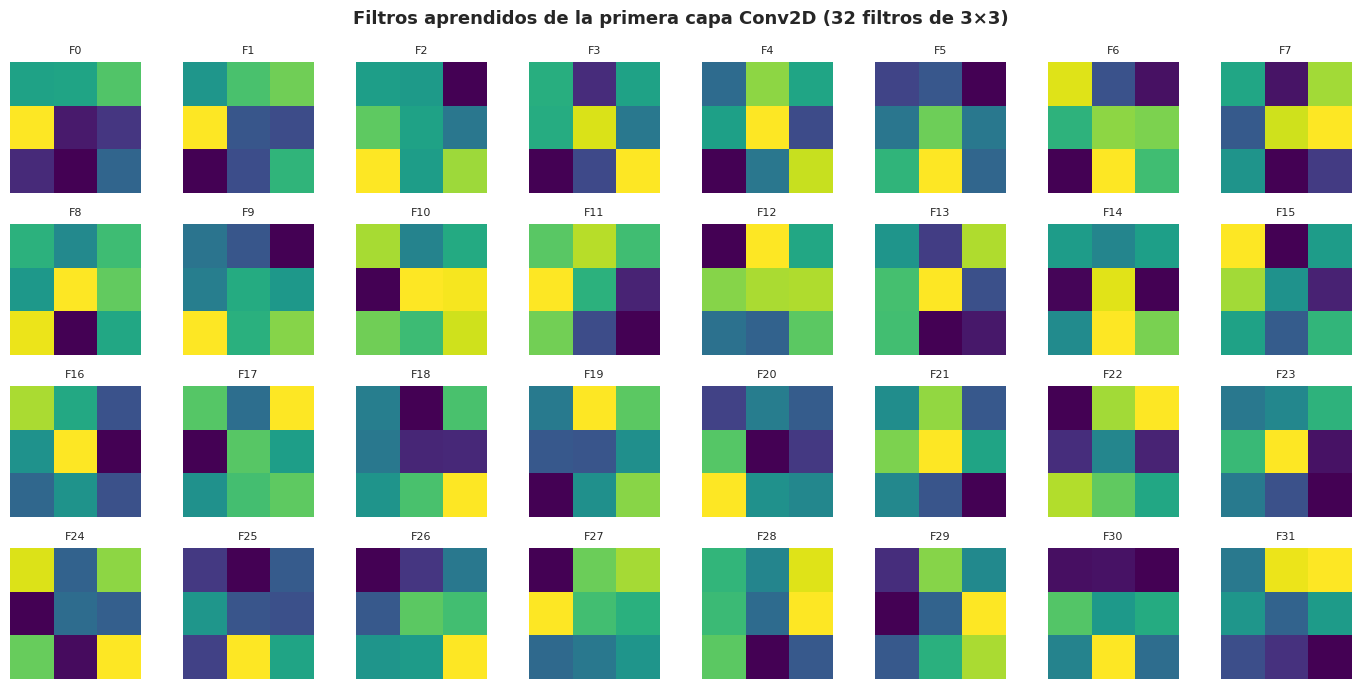

Cada filtro es un detector de patrones 3×3.
Los filtros con gradientes suaves detectan bordes en una dirección.
Los filtros con valores extremos en las esquinas detectan texturas.


In [20]:
# ============================================================
# 4.1 FILTROS DE LA PRIMERA CAPA CONVOLUCIONAL
# ============================================================
# Los filtros de la primera capa aprenden a detectar patrones básicos:
# bordes horizontales, verticales, diagonales, etc.
# Son los únicos filtros interpretables directamente como imágenes.

# Usamos la CNN mejorada para la interpretabilidad
# Encontrar la primera capa Conv2D
primera_conv = None
for layer in model_mejorada.layers:
    if isinstance(layer, layers.Conv2D):
        primera_conv = layer
        break

filtros = primera_conv.get_weights()[0]  # shape: (3, 3, 1, 32)
n_filtros = filtros.shape[-1]

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    if i < n_filtros:
        # Normalizar el filtro para visualización
        f = filtros[:, :, 0, i]
        f = (f - f.min()) / (f.max() - f.min() + 1e-8)
        ax.imshow(f, cmap='viridis', interpolation='nearest')
        ax.set_title(f'F{i}', fontsize=8)
    ax.axis('off')

plt.suptitle(f'Filtros aprendidos de la primera capa Conv2D ({n_filtros} filtros de 3×3)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Cada filtro es un detector de patrones 3×3.")
print("Los filtros con gradientes suaves detectan bordes en una dirección.")
print("Los filtros con valores extremos en las esquinas detectan texturas.")

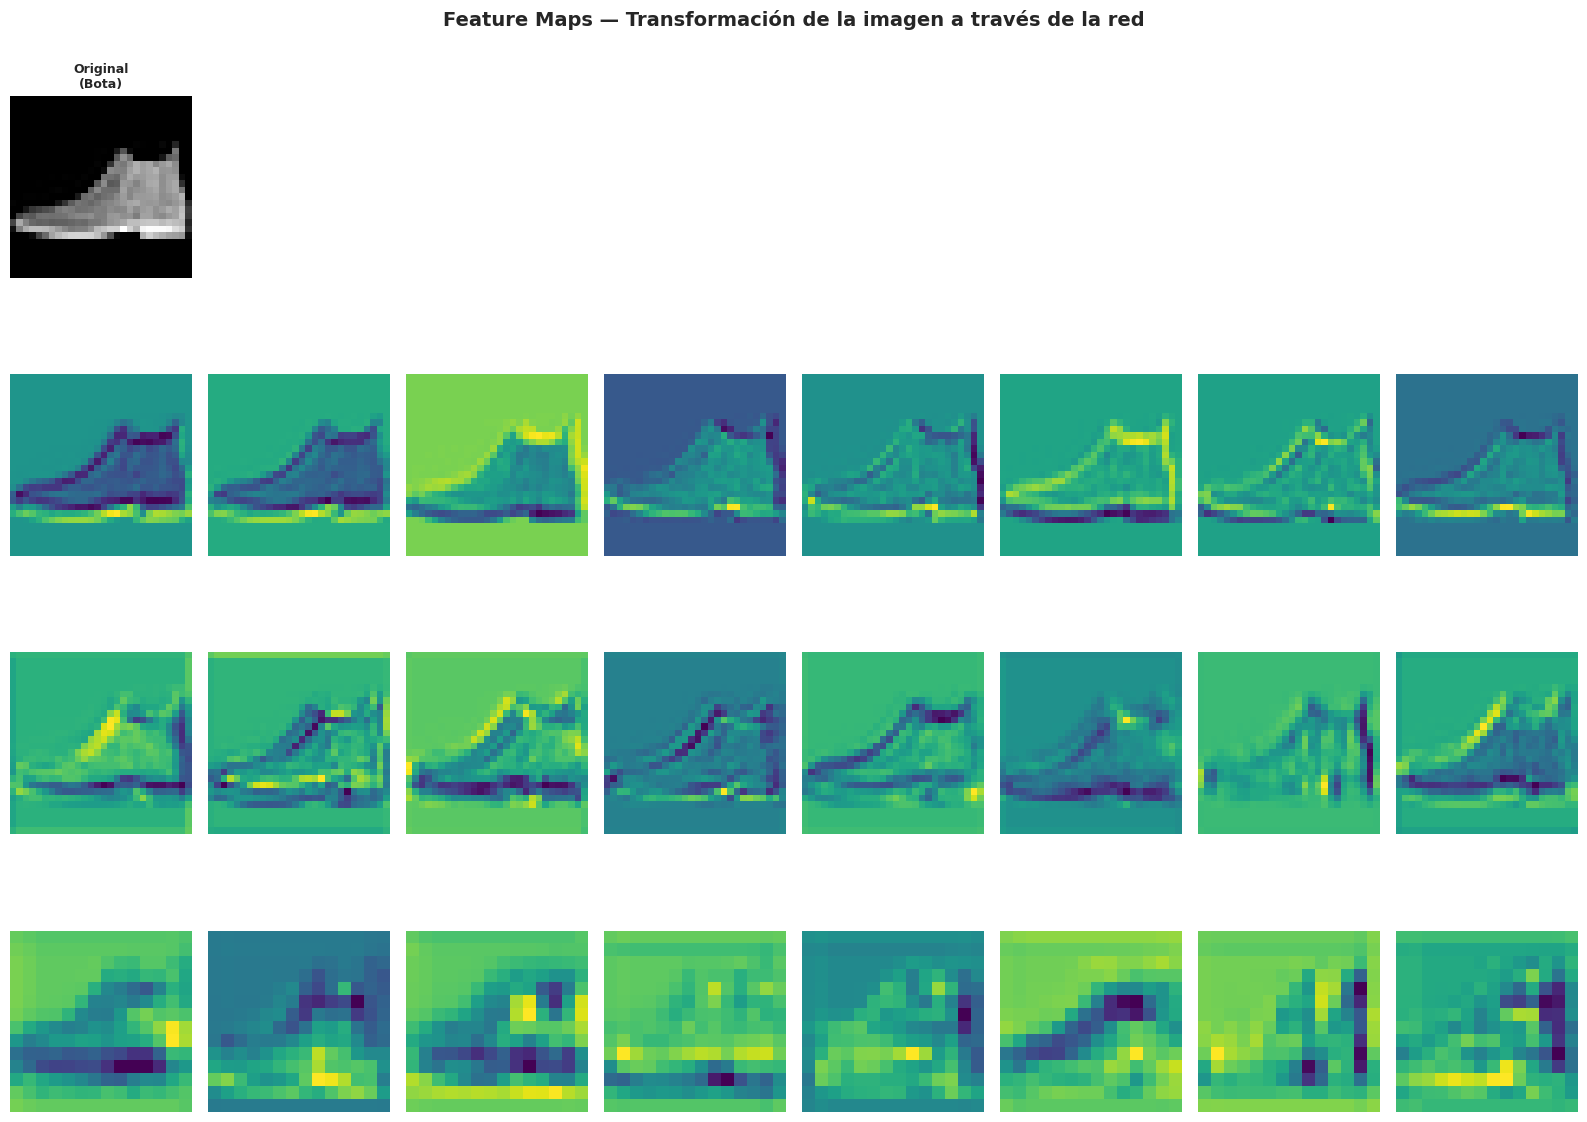

Observaciones:
  • Las primeras capas capturan bordes y texturas
  • Las capas intermedias combinan patrones en formas
  • Las capas profundas son abstractas (difíciles de interpretar visualmente)


In [21]:
# ============================================================
# 4.2 FEATURE MAPS — Activaciones intermedias
# ============================================================
# Visualizamos cómo la imagen se transforma al pasar por las capas.
# Cada capa conv produce un feature map por filtro.

# Seleccionar capas de interés (las convoluciones principales)
conv_layers = [l for l in model_mejorada.layers if isinstance(l, layers.Conv2D)]
layer_names = [l.name for l in conv_layers]
layer_outputs = [l.output for l in conv_layers]

# Modelo auxiliar que extrae las activaciones intermedias
activation_model = models.Model(inputs=model_mejorada.input, outputs=layer_outputs)

# Elegir una imagen de test
img_idx = 0  # Primer ejemplo del test
img = x_test[img_idx:img_idx+1]
activations = activation_model.predict(img, verbose=0)

# Visualizar 8 feature maps de las primeras 3 capas conv
n_capas_mostrar = min(3, len(activations))
fig, axes = plt.subplots(n_capas_mostrar + 1, 8, figsize=(16, 3*(n_capas_mostrar+1)))

# Fila 0: imagen original
axes[0, 0].imshow(img[0].squeeze(), cmap='gray')
axes[0, 0].set_title(f'Original\n({class_names[y_test[img_idx]]})', fontsize=9, fontweight='bold')
for j in range(1, 8):
    axes[0, j].axis('off')
axes[0, 0].axis('off')

# Filas 1+: feature maps de cada capa
for i, (act, name) in enumerate(zip(activations[:n_capas_mostrar],
                                     layer_names[:n_capas_mostrar])):
    for j in range(8):
        if j < act.shape[-1]:
            axes[i+1, j].imshow(act[0, :, :, j], cmap='viridis')
            if j == 0:
                axes[i+1, j].set_ylabel(name, fontsize=8, rotation=0, labelpad=50)
        axes[i+1, j].axis('off')

plt.suptitle('Feature Maps — Transformación de la imagen a través de la red',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observaciones:")
print("  • Las primeras capas capturan bordes y texturas")
print("  • Las capas intermedias combinan patrones en formas")
print("  • Las capas profundas son abstractas (difíciles de interpretar visualmente)")

In [22]:
# ============================================================
# 4.3 GRAD-CAM — ¿Dónde mira el modelo?
# ============================================================
# Grad-CAM (Gradient-weighted Class Activation Mapping) identifica
# qué REGIONES de la imagen son más importantes para la predicción.
# Usa los gradientes de la clase predicha respecto a la última capa conv.

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """
    Genera un heatmap Grad-CAM para una imagen.

    Args:
        img_array: imagen de entrada (batch de 1)
        model: modelo Keras entrenado
        last_conv_layer_name: nombre de la última capa convolucional
        pred_index: índice de la clase (None = clase predicha)

    Returns:
        heatmap normalizado (0 a 1)
    """
    # Modelo auxiliar: entrada → [última conv output, predicción]
    grad_model = models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Calcular gradientes
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    # Gradientes de la clase respecto a la salida de la última conv
    grads = tape.gradient(class_channel, conv_output)

    # Pesos: promedio global de los gradientes por canal
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplicar cada canal por su importancia y sumar
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalizar entre 0 y 1 (ReLU para quedarnos solo con las contribuciones positivas)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def visualizar_gradcam(img, heatmap, titulo='', alpha=0.4):
    """Superpone el heatmap Grad-CAM sobre la imagen original."""
    # Redimensionar heatmap al tamaño de la imagen
    import cv2
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 3.5))

    # Imagen original
    ax1.imshow(img, cmap='gray')
    ax1.set_title('Original', fontweight='bold')
    ax1.axis('off')

    # Heatmap solo
    ax2.imshow(heatmap_resized, cmap='jet')
    ax2.set_title('Grad-CAM', fontweight='bold')
    ax2.axis('off')

    # Superposición
    ax3.imshow(img, cmap='gray')
    ax3.imshow(heatmap_resized, cmap='jet', alpha=alpha)
    ax3.set_title(titulo, fontweight='bold')
    ax3.axis('off')

    plt.tight_layout()
    plt.show()

print("✅ Funciones Grad-CAM definidas.")

✅ Funciones Grad-CAM definidas.


Última capa conv: conv2d_14


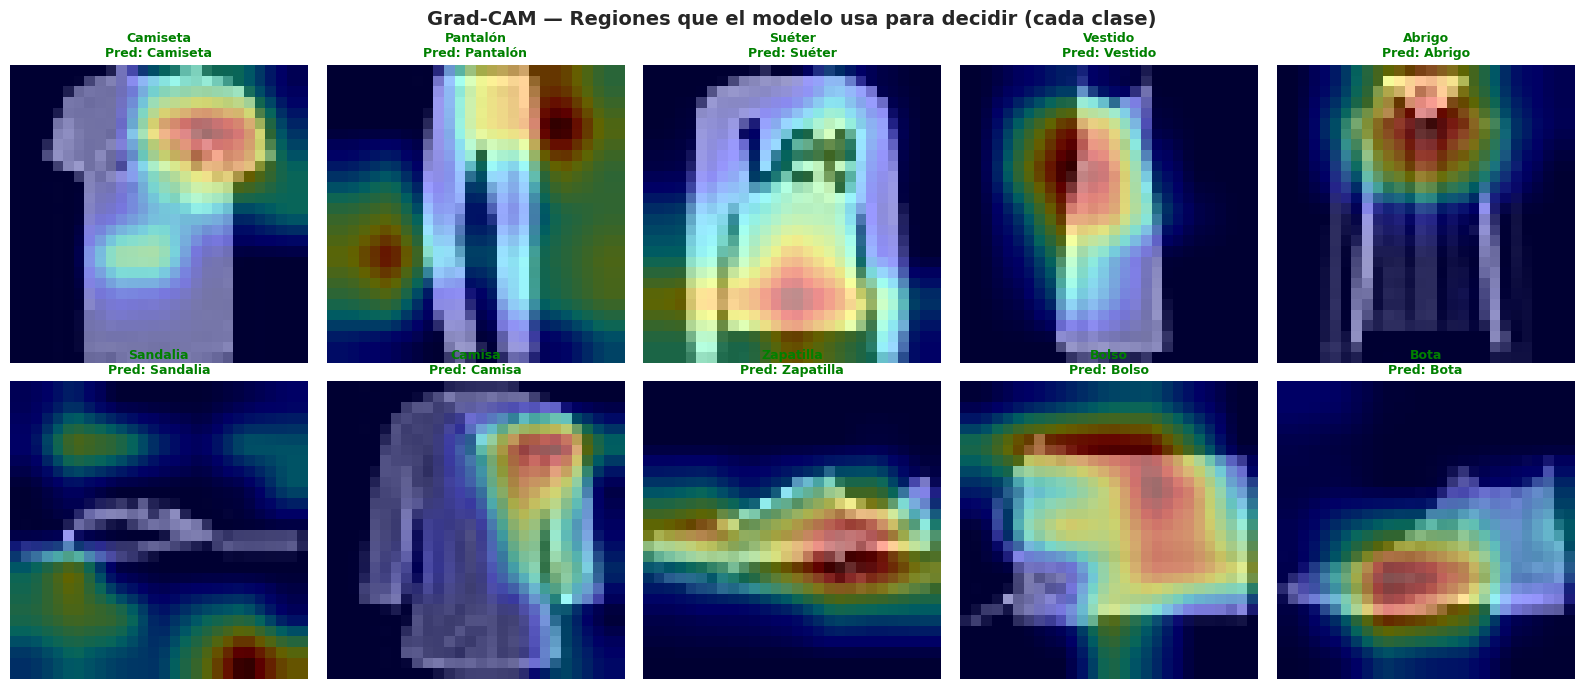

🔴 Rojo/amarillo = regiones más importantes para la predicción
🔵 Azul = regiones menos relevantes


In [23]:
# ============================================================
# GRAD-CAM — Aplicación a múltiples ejemplos
# ============================================================
# Encontrar la última capa convolucional de la CNN mejorada
last_conv_name = None
for layer in reversed(model_mejorada.layers):
    if isinstance(layer, layers.Conv2D):
        last_conv_name = layer.name
        break
print(f"Última capa conv: {last_conv_name}")

# Seleccionar un ejemplo de cada clase
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for i, ax in enumerate(axes.flat):
    idx = np.where(y_test == i)[0][0]
    img = x_test[idx:idx+1]
    pred = np.argmax(model_mejorada.predict(img, verbose=0))

    heatmap = make_gradcam_heatmap(img, model_mejorada, last_conv_name)

    # Redimensionar
    import cv2
    heatmap_resized = cv2.resize(heatmap, (28, 28))

    ax.imshow(x_test[idx].squeeze(), cmap='gray')
    ax.imshow(heatmap_resized, cmap='jet', alpha=0.4)
    color = 'green' if pred == y_test[idx] else 'red'
    ax.set_title(f'{class_names[y_test[idx]]}\nPred: {class_names[pred]}',
                 fontsize=9, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle('Grad-CAM — Regiones que el modelo usa para decidir (cada clase)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("🔴 Rojo/amarillo = regiones más importantes para la predicción")
print("🔵 Azul = regiones menos relevantes")

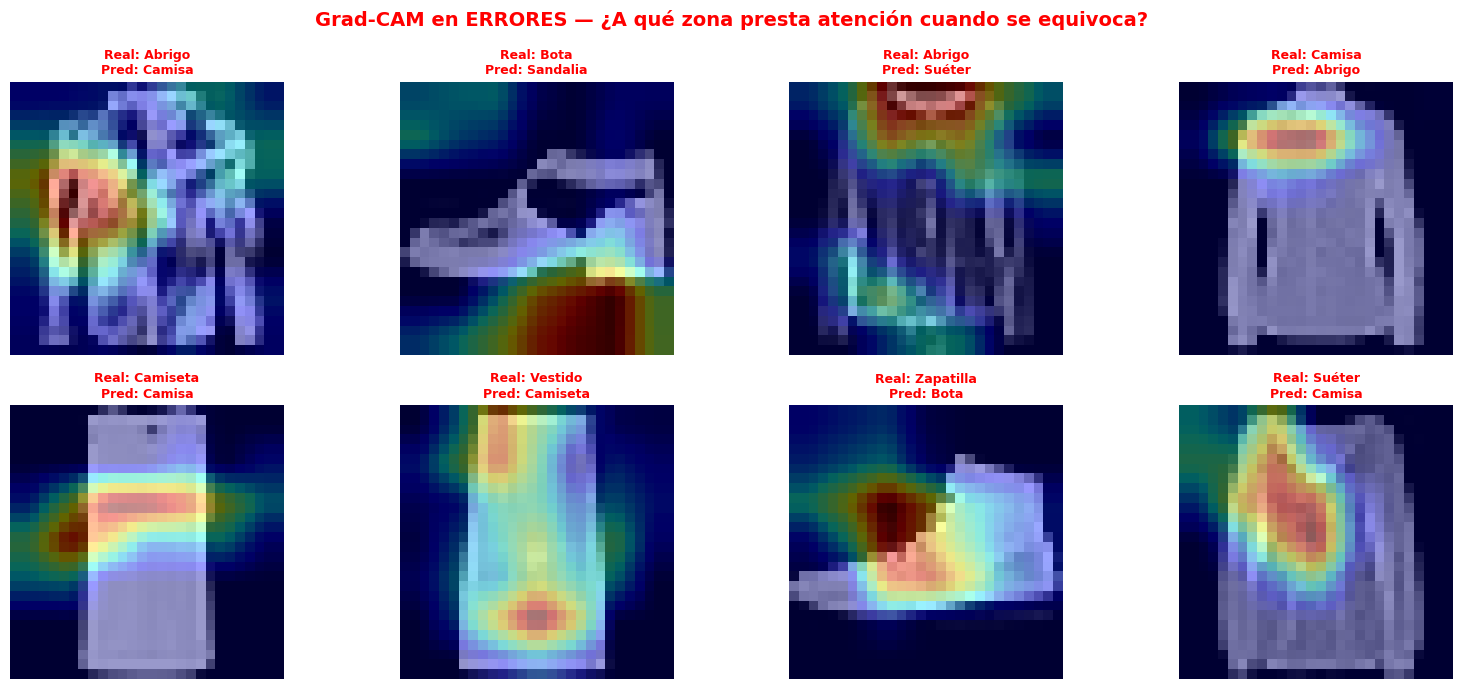

En los errores, el modelo suele atender regiones ambiguas
(cuello de una camisa vs camiseta, textura de suéter vs abrigo, etc.)


In [24]:
# ============================================================
# GRAD-CAM — Casos de error (¿dónde mira cuando se equivoca?)
# ============================================================
y_pred_mej = np.argmax(model_mejorada.predict(x_test, verbose=0), axis=1)
errores_mej = np.where(y_pred_mej != y_test)[0]

n_show = min(8, len(errores_mej))
fig, axes = plt.subplots(2, n_show//2, figsize=(16, 7))

for ax, idx in zip(axes.flat, errores_mej[:n_show]):
    img = x_test[idx:idx+1]
    heatmap = make_gradcam_heatmap(img, model_mejorada, last_conv_name)
    heatmap_resized = cv2.resize(heatmap, (28, 28))

    ax.imshow(x_test[idx].squeeze(), cmap='gray')
    ax.imshow(heatmap_resized, cmap='jet', alpha=0.4)
    ax.set_title(f'Real: {class_names[y_test[idx]]}\nPred: {class_names[y_pred_mej[idx]]}',
                 fontsize=9, color='red', fontweight='bold')
    ax.axis('off')

plt.suptitle('Grad-CAM en ERRORES — ¿A qué zona presta atención cuando se equivoca?',
             fontsize=14, fontweight='bold', color='red')
plt.tight_layout()
plt.show()

print("En los errores, el modelo suele atender regiones ambiguas")
print("(cuello de una camisa vs camiseta, textura de suéter vs abrigo, etc.)")

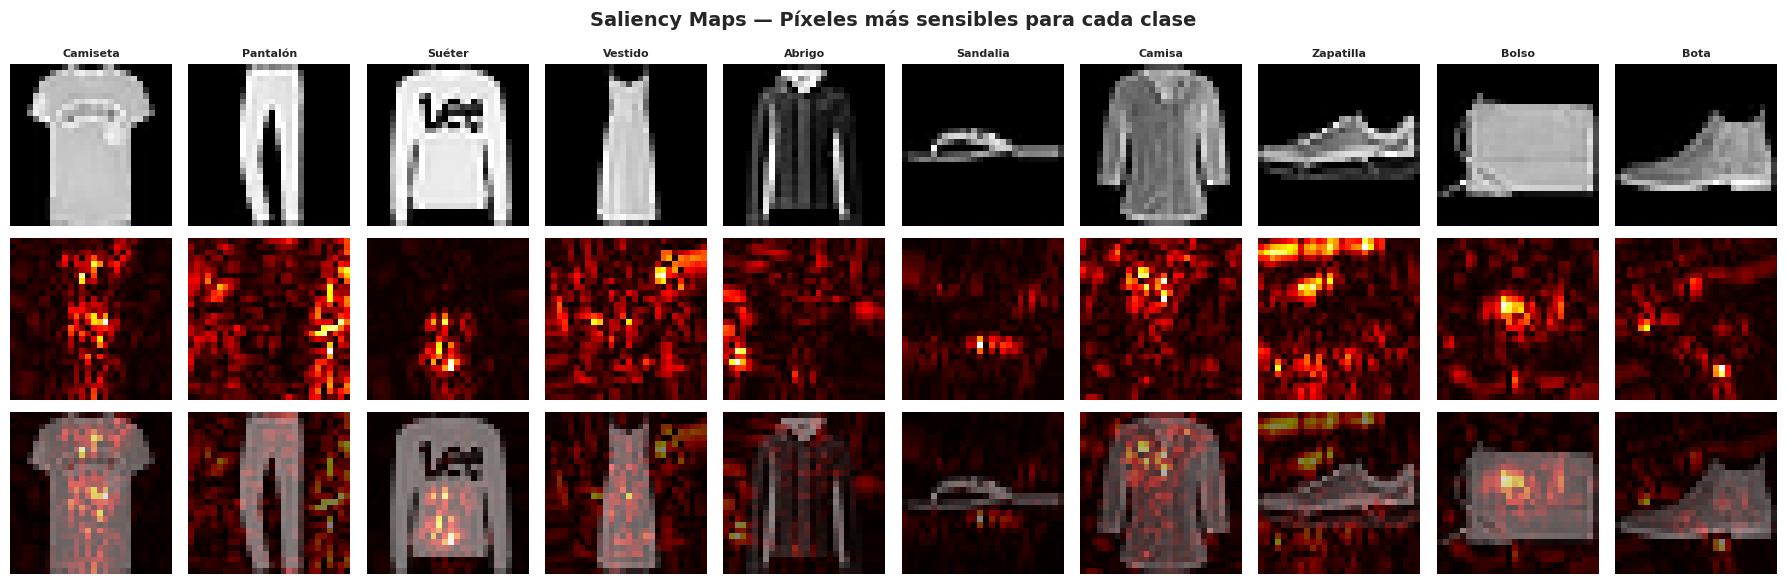

Los saliency maps muestran qué PÍXELES son más críticos.
A diferencia de Grad-CAM (que muestra regiones), estos tienen resolución por píxel.


In [25]:
# ============================================================
# 4.4 SALIENCY MAPS — Sensibilidad por píxel
# ============================================================
# Saliency map = gradiente de la predicción respecto a los PÍXELES de entrada.
# Muestra qué píxeles, al cambiar ligeramente, más afectan la predicción.
# Complementario a Grad-CAM: resolución por píxel vs por región.

def compute_saliency(model, image, class_idx=None):
    """
    Calcula el mapa de saliencia (gradiente de la predicción vs entrada).

    Args:
        model: modelo Keras
        image: tensor de imagen (batch de 1)
        class_idx: índice de la clase (None = clase predicha)

    Returns:
        saliency map normalizado
    """
    image_tensor = tf.cast(image, tf.float32)
    image_tensor = tf.Variable(image_tensor)  # Necesario para calcular gradientes

    with tf.GradientTape() as tape:
        tape.watch(image_tensor)
        predictions = model(image_tensor)
        if class_idx is None:
            class_idx = tf.argmax(predictions[0])
        target = predictions[0, class_idx]

    # Gradiente de la predicción respecto a cada píxel
    gradients = tape.gradient(target, image_tensor)

    # Valor absoluto → magnitud del gradiente (sin importar la dirección)
    saliency = tf.abs(gradients[0])

    # Si hay canal, tomar el máximo a través de los canales
    if len(saliency.shape) == 3:
        saliency = tf.reduce_max(saliency, axis=-1)

    # Normalizar a [0, 1]
    saliency = saliency / (tf.reduce_max(saliency) + 1e-8)
    return saliency.numpy()


# Visualizar saliency maps para un ejemplo de cada clase
fig, axes = plt.subplots(3, 10, figsize=(18, 6))

for i in range(10):
    idx = np.where(y_test == i)[0][0]
    img = x_test[idx:idx+1]
    sal = compute_saliency(model_mejorada, img)

    # Fila 1: Imagen original
    axes[0, i].imshow(x_test[idx].squeeze(), cmap='gray')
    axes[0, i].set_title(class_names[i], fontsize=8, fontweight='bold')
    axes[0, i].axis('off')

    # Fila 2: Saliency map
    axes[1, i].imshow(sal, cmap='hot')
    axes[1, i].axis('off')

    # Fila 3: Superposición
    axes[2, i].imshow(x_test[idx].squeeze(), cmap='gray')
    axes[2, i].imshow(sal, cmap='hot', alpha=0.5)
    axes[2, i].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=10, rotation=0, labelpad=50)
axes[1, 0].set_ylabel('Saliency', fontsize=10, rotation=0, labelpad=50)
axes[2, 0].set_ylabel('Overlay', fontsize=10, rotation=0, labelpad=50)

plt.suptitle('Saliency Maps — Píxeles más sensibles para cada clase',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Los saliency maps muestran qué PÍXELES son más críticos.")
print("A diferencia de Grad-CAM (que muestra regiones), estos tienen resolución por píxel.")

---
## BLOQUE 5 — Síntesis y Conclusiones

In [26]:
# ============================================================
# REPORTE FINAL — CNN Mejorada en Test
# ============================================================
y_pred_final = np.argmax(model_mejorada.predict(x_test, verbose=0), axis=1)

print("=" * 60)
print("REPORTE FINAL — CNN Mejorada")
print("=" * 60)
print(classification_report(y_test, y_pred_final,
      target_names=class_names, digits=4))

# Tabla resumen
import pandas as pd
resumen = pd.DataFrame({
    'Modelo': ['CNN Base', 'CNN Mejorada', 'Mini-ResNet'],
    'Parámetros': [f'{model_base.count_params():,}',
                   f'{model_mejorada.count_params():,}',
                   f'{model_resnet.count_params():,}'],
    'Test Accuracy': [f'{acc_base:.4f}', f'{acc_mej:.4f}', f'{acc_res:.4f}'],
    'Regularización': ['Ninguna',
                       'BN + Dropout + Aug',
                       'BN + Dropout + Aug + Skip + LR Schedule'],
    'Interpretabilidad': ['—', 'Filtros + GradCAM + Saliency', 'Filtros + GradCAM + Saliency']
})
print("\n" + resumen.to_string(index=False))

REPORTE FINAL — CNN Mejorada
              precision    recall  f1-score   support

    Camiseta     0.8917    0.7990    0.8428      1000
    Pantalón     0.9889    0.9770    0.9829      1000
      Suéter     0.8836    0.8580    0.8706      1000
     Vestido     0.9068    0.8760    0.8911      1000
      Abrigo     0.8139    0.8880    0.8494      1000
    Sandalia     0.9825    0.9520    0.9670      1000
      Camisa     0.6832    0.7420    0.7114      1000
   Zapatilla     0.9136    0.9730    0.9424      1000
       Bolso     0.9742    0.9810    0.9776      1000
        Bota     0.9750    0.9370    0.9556      1000

    accuracy                         0.8983     10000
   macro avg     0.9014    0.8983    0.8991     10000
weighted avg     0.9014    0.8983    0.8991     10000


      Modelo Parámetros Test Accuracy                          Regularización            Interpretabilidad
    CNN Base    467,818        0.9206                                 Ninguna                           

---
## Conclusiones

### Evaluación
- La **accuracy global** oculta diferencias entre clases — el reporte por clase es esencial.
- La **matriz de confusión** revela confusiones semánticas (Camisa↔Camiseta, Suéter↔Abrigo).
- Las **curvas ROC por clase** identifican cuáles clases el modelo separa mejor/peor.
- El **análisis de errores** visual revela patrones de fallo y sugiere mejoras.

### Optimización y Regularización
- **Data Augmentation** es la regularización más efectiva en visión — genera diversidad sin más datos.
- **BatchNorm** estabiliza el entrenamiento y permite learning rates más altos.
- **Dropout en capas conv** y **GAP** reducen parámetros y overfitting.
- **Skip connections** (ResNet) permiten entrenar redes más profundas sin degradación.
- **LR Schedule** produce mejoras significativas en las épocas finales.

### Interpretabilidad
- **Filtros de conv1:** muestran los detectores de bordes aprendidos (bajo nivel).
- **Feature maps:** revelan la transformación progresiva de la imagen.
- **Grad-CAM:** localiza las regiones de la imagen decisivas para la clasificación.
- **Saliency maps:** resolución por píxel, complementario a Grad-CAM.
- Los **errores analizados con Grad-CAM** revelan que el modelo atiende regiones ambiguas.

### Versión A vs Versión B
| Aspecto | Versión A (MLPs) | Versión B (CNNs) |
|---------|-----------------|------------------|
| Datos | Tabulares (30 features numéricas) | Imágenes (28×28 píxeles) |
| Interpretabilidad | SHAP, Permutation Importance | Grad-CAM, Saliency Maps |
| Regularización clave | Dropout, L2, BatchNorm | Data Augmentation, Skip connections |
| Fortaleza | Explicabilidad feature-level | Explicabilidad espacial/visual |

---

*Notebook Versión B — Redes Profundas (CNNs) | ISO56B | UNCP*